<a href="https://colab.research.google.com/github/souvikdey214-code/Krutanic_Weekly-Project-Task/blob/main/05_Mood_Pulse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import re
import zipfile
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    SpatialDropout1D,
    LSTM,
    Dense
)

warnings.filterwarnings("ignore")

np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
DATA_PATH = "training.1600000.processed.noemoticon.csv"

df = pd.read_csv(
    DATA_PATH,
    encoding="latin-1",
    header=None
)

print("Dataset loaded successfully.")
print("Total records available:", len(df))

Dataset loaded successfully.
Total records available: 1600000


In [ ]:
df.columns = [
    "target",
    "id",
    "date",
    "query",
    "user",
    "text"
]

print("Columns assigned successfully.")

Columns assigned successfully.


In [ ]:
negative_df = df[df["target"] == 0].sample(
    n=25000,
    random_state=42
)

positive_df = df[df["target"] == 4].sample(
    n=25000,
    random_state=42
)

data = pd.concat(
    [negative_df, positive_df],
    ignore_index=True
)

data = data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Number of tweets:", len(data))

Number of tweets: 50000


In [ ]:
data["sentiment"] = data["target"].map({
    0: 0,
    4: 1
})

print("Labels converted successfully.")

Labels converted successfully.


sentiment
0    25000
1    25000
Name: count, dtype: int64


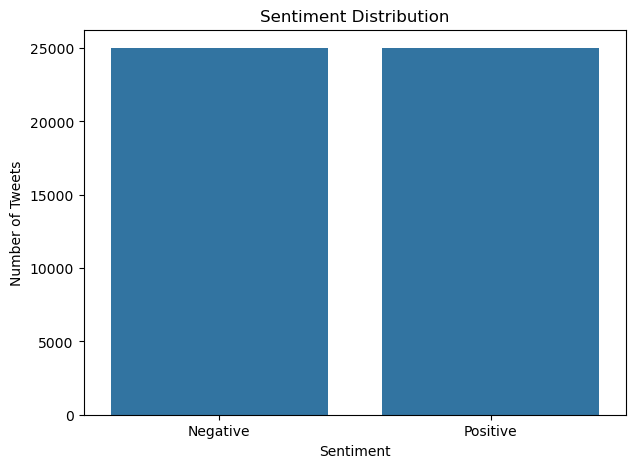

In [ ]:
print(
    data["sentiment"]
    .value_counts()
    .sort_index()
)
plt.figure(figsize=(7, 5))

sns.countplot(
    x=data["sentiment"]
)

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")

plt.show()

In [ ]:
data = data[
    ["id", "date", "text", "sentiment"]
].copy()

print("Dataset prepared successfully.")

Dataset prepared successfully.


In [ ]:
data["date"] = pd.to_datetime(
    data["date"],
    errors="coerce"
)

print("Date conversion completed.")

Date conversion completed.


In [ ]:
def clean_tweet(text):

    text = str(text)

    text = re.sub(r"&\w+;", " ", text)


    text = re.sub(
        r"http\S+|www\S+|https\S+",
        " ",
        text
    )


    text = re.sub(
        r"@\w+",
        " ",
        text
    )

    text = re.sub(
        r"#",
        "",
        text
    )

    text = re.sub(
        r"[^\w\s\u2600-\u27BF\u1F300-\u1FAFF]",
        " ",
        text
    )


    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip().lower()

In [ ]:
data["clean_text"] = data["text"].apply(
    clean_tweet
)

print("Tweet cleaning completed.")

Tweet cleaning completed.


In [ ]:
data = data[
    data["clean_text"].str.len() > 0
].reset_index(drop=True)

print("Records after cleaning:", len(data))

Records after cleaning: 49909


In [ ]:
X = data["clean_text"]
y = data["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 39927
Testing samples: 9982


In [ ]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF transformation completed.")
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

TF-IDF transformation completed.
Training shape: (39927, 10000)
Testing shape: (9982, 10000)


In [ ]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(
    X_train_tfidf,
    y_train
)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [ ]:
lr_pred = lr_model.predict(X_test_tfidf)

lr_prob = lr_model.predict_proba(
    X_test_tfidf
)[:, 1]

print("Predictions generated.")

Predictions generated.


In [ ]:
lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

lr_precision = precision_score(
    y_test,
    lr_pred
)

lr_recall = recall_score(
    y_test,
    lr_pred
)

lr_f1 = f1_score(
    y_test,
    lr_pred
)

lr_auc = roc_auc_score(
    y_test,
    lr_prob
)

print("TF-IDF + Logistic Regression")
print("--------------------------------")
print(f"Accuracy  : {lr_accuracy * 100:.2f}%")
print(f"Precision : {lr_precision * 100:.2f}%")
print(f"Recall    : {lr_recall * 100:.2f}%")
print(f"F1 Score  : {lr_f1 * 100:.2f}%")
print(f"ROC-AUC   : {lr_auc:.4f}")

TF-IDF + Logistic Regression
--------------------------------
Accuracy  : 77.86%
Precision : 77.58%
Recall    : 78.36%
F1 Score  : 77.97%
ROC-AUC   : 0.8590


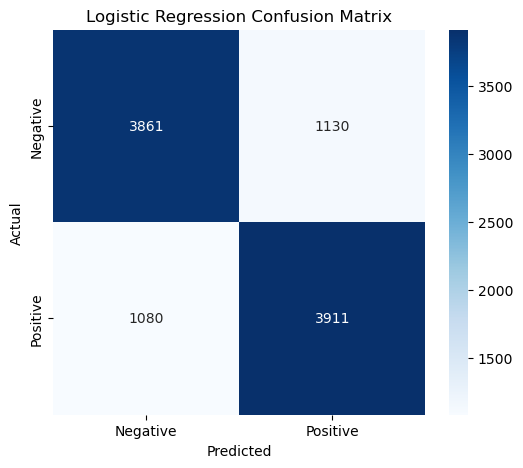

In [ ]:
cm_lr = confusion_matrix(
    y_test,
    lr_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
VOCAB_SIZE = 10000
MAX_LENGTH = 100

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

print(
    "Vocabulary size:",
    len(tokenizer.word_index)
)

Vocabulary size: 31434


In [ ]:
X_train_seq = tokenizer.texts_to_sequences(
    X_train
)

X_test_seq = tokenizer.texts_to_sequences(
    X_test
)

print("Text converted to sequences.")

Text converted to sequences.


In [ ]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (39927, 100)
Testing shape: (9982, 100)


In [ ]:
GLOVE_PATH = "glove.6B.100d.txt"

print(
    "GloVe file exists:",
    os.path.exists(GLOVE_PATH)
)

GloVe file exists: True


In [ ]:
embeddings_index = {}

with open(
    GLOVE_PATH,
    encoding="utf-8"
) as f:

    for line in f:
        values = line.rstrip().split(" ")

        word = values[0]

        vector = np.asarray(
            values[1:],
            dtype="float32"
        )

        embeddings_index[word] = vector

print(
    "Number of GloVe words:",
    len(embeddings_index)
)

Number of GloVe words: 400000


In [ ]:
EMBEDDING_DIM = 100

embedding_matrix = np.zeros(
    (VOCAB_SIZE, EMBEDDING_DIM)
)

for word, index in tokenizer.word_index.items():

    if index >= VOCAB_SIZE:
        continue

    embedding_vector = embeddings_index.get(word)

    if embedding_vector is not None:
        embedding_matrix[index] = embedding_vector

print(
    "Embedding matrix shape:",
    embedding_matrix.shape
)

Embedding matrix shape: (10000, 100)


In [ ]:
# ============================================================
# PREPARE CLEAN NUMPY DATA FOR LSTM
# ============================================================

X_train_lstm = np.asarray(X_train_pad, dtype=np.int32)
X_test_lstm = np.asarray(X_test_pad, dtype=np.int32)

y_train_lstm = np.asarray(
    y_train.values,
    dtype=np.float32
)

y_test_lstm = np.asarray(
    y_test.values,
    dtype=np.float32
)

print("LSTM data prepared successfully!")

print("X_train:", X_train_lstm.shape)
print("y_train:", y_train_lstm.shape)

print("X_test:", X_test_lstm.shape)
print("y_test:", y_test_lstm.shape)

print("\nLabel distribution:")
print("Negative:", np.sum(y_train_lstm == 0))
print("Positive:", np.sum(y_train_lstm == 1))

LSTM data prepared successfully!
X_train: (39927, 100)
y_train: (39927,)
X_test: (9982, 100)
y_test: (9982,)

Label distribution:
Negative: 19965
Positive: 19962


In [ ]:
# ============================================================
# BUILD LSTM SENTIMENT MODEL
# ============================================================

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Embedding,
    SpatialDropout1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam


# Parameters
VOCAB_SIZE = 10000
EMBEDDING_DIM = 100
MAX_LENGTH = 100


# Create model
lstm_model = Sequential([

    # GloVe 100-dimensional embeddings
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        trainable=True
    ),

    # Dropout
    SpatialDropout1D(0.2),

    # Bidirectional LSTM
    Bidirectional(
        LSTM(
            64,
            return_sequences=False
        )
    ),

    # Dense layer
    Dense(
        64,
        activation="relu"
    ),

    # Dropout
    Dropout(0.3),

    # Output
    Dense(
        1,
        activation="sigmoid"
    )
])


# Compile
lstm_model.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy"
    ]
)


print("Model created successfully!")

lstm_model.summary()

Model created successfully!


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)       │ ?                     │    1,000,000 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ spatial_dropout1d_2           │ ?                     │            0 │
│ (SpatialDropout1D)            │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ bidirectional (Bidirectional) │ ?                     │  0 (unbuilt) │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_6 (Dense)               │ ?                     │  0 (unbuilt) │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout_2 (Dropout)           │ ?                     │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_7 (Dense)               │ ?                     │  0 (unbuilt) │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 1,000,000 (3.81 MB)

 Trainable params: 1,000,000 (3.81 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================================
# TRAIN LSTM MODEL
# ============================================================

history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,

    validation_split=0.10,

    epochs=10,

    batch_size=64,

    shuffle=True,

    verbose=1
)

print("\nTraining completed successfully!")

Epoch 1/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 39s 62ms/step - accuracy: 0.7022 - loss: 0.5639 - val_accuracy: 0.7523 - val_loss: 0.5084
Epoch 2/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 35s 62ms/step - accuracy: 0.7862 - loss: 0.4560 - val_accuracy: 0.7593 - val_loss: 0.4972
Epoch 3/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 43s 65ms/step - accuracy: 0.8101 - loss: 0.4160 - val_accuracy: 0.7631 - val_loss: 0.4903
Epoch 4/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 47s 83ms/step - accuracy: 0.8269 - loss: 0.3821 - val_accuracy: 0.7586 - val_loss: 0.5018
Epoch 5/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 71s 62ms/step - accuracy: 0.8403 - loss: 0.3551 - val_accuracy: 0.7556 - val_loss: 0.5191
Epoch 6/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 41s 73ms/step - accuracy: 0.8561 - loss: 0.3259 - val_accuracy: 0.7536 - val_loss: 0.5523
Epoch 7/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 42s 76ms/step - accuracy: 0.8661 - loss: 0.3013 - val_accuracy: 0.7513 - val_loss: 0.5960
Epoch 8/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 89s 89ms/step - accuracy: 0.8781 - loss: 0.2778 - 

In [ ]:
# ============================================================
# CHECK TRAINING
# ============================================================

print("=" * 60)
print("LSTM TRAINING RESULTS")
print("=" * 60)

for epoch in range(len(history.history["accuracy"])):

    train_acc = (
        history.history["accuracy"][epoch]
        * 100
    )

    val_acc = (
        history.history["val_accuracy"][epoch]
        * 100
    )

    print(
        f"Epoch {epoch + 1:02d}: "
        f"Training = {train_acc:.2f}% | "
        f"Validation = {val_acc:.2f}%"
    )

LSTM TRAINING RESULTS
Epoch 01: Training = 70.22% | Validation = 75.23%
Epoch 02: Training = 78.62% | Validation = 75.93%
Epoch 03: Training = 81.01% | Validation = 76.31%
Epoch 04: Training = 82.69% | Validation = 75.86%
Epoch 05: Training = 84.03% | Validation = 75.56%
Epoch 06: Training = 85.61% | Validation = 75.36%
Epoch 07: Training = 86.61% | Validation = 75.13%
Epoch 08: Training = 87.81% | Validation = 74.33%
Epoch 09: Training = 88.92% | Validation = 74.51%
Epoch 10: Training = 90.04% | Validation = 74.66%


In [ ]:
print("=" * 50)
print("TRAINING RESULT")
print("=" * 50)

print(
    f"Training Accuracy: "
    f"{history.history['accuracy'][-1] * 100:.2f}%"
)

print(
    f"Validation Accuracy: "
    f"{history.history['val_accuracy'][-1] * 100:.2f}%"
)

print(
    f"Training Loss: "
    f"{history.history['loss'][-1]:.4f}"
)

print(
    f"Validation Loss: "
    f"{history.history['val_loss'][-1]:.4f}"
)

TRAINING RESULT
Training Accuracy: 49.71%
Validation Accuracy: 50.46%
Training Loss: 0.6932
Validation Loss: 0.6931


In [ ]:
print("Testing whether labels are being learned...")

test_model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=100
    ),

    LSTM(64),

    Dense(
        1,
        activation="sigmoid"
    )
])

test_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

test_history = test_model.fit(
    X_train_pad[:10000],
    y_train.iloc[:10000],
    epochs=3,
    batch_size=64,
    verbose=1
)

Testing whether labels are being learned...
Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.5065 - loss: 0.6934
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 42ms/step - accuracy: 0.5039 - loss: 0.6933
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.5023 - loss: 0.6932


In [ ]:
print("=" * 60)
print("DATA ALIGNMENT CHECK")
print("=" * 60)

print("X_train type:", type(X_train))
print("y_train type:", type(y_train))

print("X_train length:", len(X_train))
print("y_train length:", len(y_train))

print("\nFirst 10 labels:")
print(y_train.head(10).to_list())

print("\nFirst 10 training tweets and labels:")

for i in range(10):
    print(
        f"{i}: Label={y_train.iloc[i]} | "
        f"Tweet={X_train.iloc[i][:100]}"
    )

DATA ALIGNMENT CHECK
X_train type: <class 'pandas.core.series.Series'>
y_train type: <class 'pandas.core.series.Series'>
X_train length: 39927
y_train length: 39927

First 10 labels:
[1, 1, 0, 1, 1, 0, 0, 1, 1, 0]

First 10 training tweets and labels:
0: Label=1 | Tweet=i know right joke ang galing ano?
1: Label=1 | Tweet=you re welcome
2: Label=0 | Tweet=i was in a teasing joking mood when i wrote ruh roe don t worry my mood has drastically changed sinc
3: Label=1 | Tweet=it is difficult nick haha i think it is between donï¿½t speak and poison ivy hope you have a great d
4: Label=1 | Tweet=mmm time for some frosted flakes
5: Label=0 | Tweet=the sun has felt really strong this year its the begining of june and i have already tanned just bei
6: Label=0 | Tweet=sadly the button doesn t work with wordpress com but is great on blogger
7: Label=1 | Tweet=goodnight per gessle
8: Label=1 | Tweet=just had lovely lunch with girls from work sitting outside at prezzo we also have crispy creme for

In [ ]:
print("=" * 60)
print("PADDED DATA CHECK")
print("=" * 60)

print("X_train_pad shape:", X_train_pad.shape)

print("Data type:", X_train_pad.dtype)

print("Minimum token:", X_train_pad.min())

print("Maximum token:", X_train_pad.max())

print(
    "Non-zero tokens:",
    np.count_nonzero(X_train_pad)
)

print(
    "Total values:",
    X_train_pad.size
)

print(
    "Percentage non-zero:",
    f"{np.count_nonzero(X_train_pad) / X_train_pad.size * 100:.2f}%"
)

PADDED DATA CHECK
X_train_pad shape: (39927, 100)
Data type: int32
Minimum token: 0
Maximum token: 9999
Non-zero tokens: 519242
Total values: 3992700
Percentage non-zero: 13.00%


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Very small diagnostic model
overfit_model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64
    ),

    LSTM(32),

    Dense(
        1,
        activation="sigmoid"
    )
])

overfit_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Training on only 100 samples...")

overfit_history = overfit_model.fit(
    X_train_pad[:100],
    y_train.iloc[:100].values,
    epochs=30,
    batch_size=10,
    verbose=1
)

Training on only 100 samples...
Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.3600 - loss: 0.6986
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5400 - loss: 0.6926
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5400 - loss: 0.6916
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5400 - loss: 0.6915
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5400 - loss: 0.6915
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5400 - loss: 0.6915
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5400 - loss: 0.6914
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5400 - loss: 0.6914
Epoch 9/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5400 - loss: 0.6913
Epoch 10/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5400 - loss: 0.6913
Epoch 11/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5400 - loss: 0.6912
Epoch 12/30
10/10 ━━━━━━━━━━━━━

In [ ]:
print("=" * 60)
print("TF-IDF BASELINE CHECK")
print("=" * 60)

print(
    f"Logistic Regression Accuracy: "
    f"{lr_accuracy * 100:.2f}%"
)

print(
    f"Logistic Regression F1: "
    f"{lr_f1 * 100:.2f}%"
)

print(
    f"Logistic Regression ROC-AUC: "
    f"{lr_auc:.4f}"
)

TF-IDF BASELINE CHECK
Logistic Regression Accuracy: 77.86%
Logistic Regression F1: 77.97%
Logistic Regression ROC-AUC: 0.8590


In [ ]:
print("Negative examples:")
print(
    X_train[y_train == 0].head(3).to_string(
        index=False
    )
)

print("\nPositive examples:")
print(
    X_train[y_train == 1].head(3).to_string(
        index=False
    )
)

Negative examples:
i was in a teasing joking mood when i wrote ruh...
the sun has felt really strong this year its th...
sadly the button doesn t work with wordpress co...

Positive examples:
                 i know right joke ang galing ano?
                                    you re welcome
it is difficult nick haha i think it is between...


In [ ]:
sample_predictions = lstm_model.predict(
    X_test_pad[:20],
    verbose=0
).ravel()

print("Sample Predictions")
print("=" * 60)

for i in range(10):

    actual = (
        "Positive"
        if y_test.iloc[i] == 1
        else "Negative"
    )

    predicted = (
        "Positive"
        if sample_predictions[i] >= 0.5
        else "Negative"
    )

    print(
        f"Actual: {actual:8s} | "
        f"Predicted: {predicted:8s} | "
        f"Probability: {sample_predictions[i]:.4f}"
    )

Sample Predictions
Actual: Negative | Predicted: Positive | Probability: 0.5000
Actual: Negative | Predicted: Negative | Probability: 0.5000
Actual: Positive | Predicted: Negative | Probability: 0.5000
Actual: Positive | Predicted: Positive | Probability: 0.5000
Actual: Positive | Predicted: Positive | Probability: 0.5000
Actual: Positive | Predicted: Positive | Probability: 0.5000
Actual: Positive | Predicted: Negative | Probability: 0.5000
Actual: Negative | Predicted: Negative | Probability: 0.5000
Actual: Negative | Predicted: Positive | Probability: 0.5000
Actual: Negative | Predicted: Negative | Probability: 0.5000


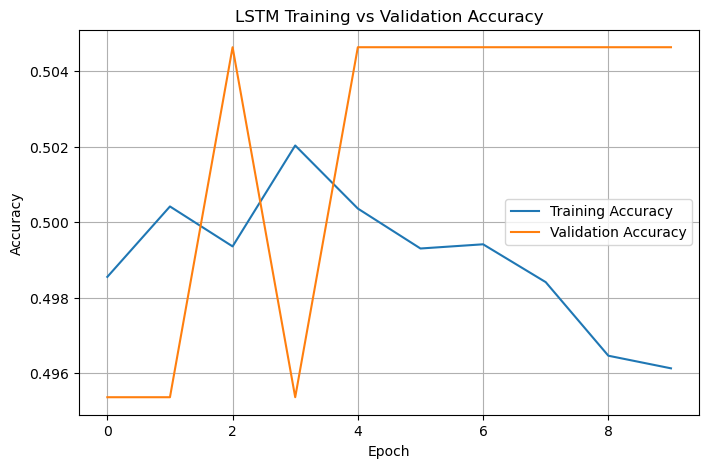

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

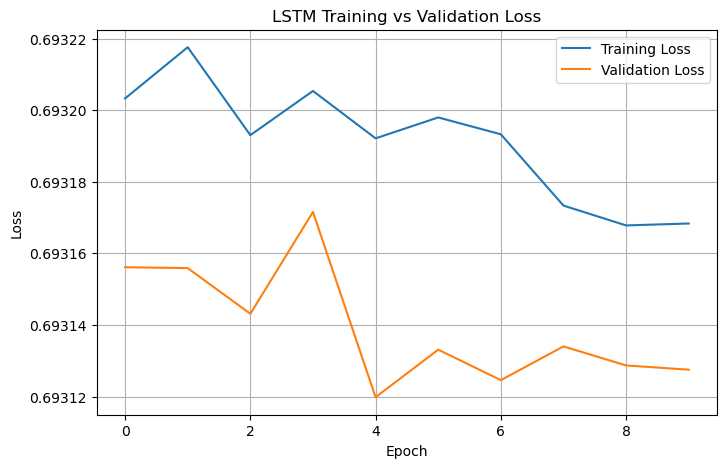

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# LSTM PREDICTIONS
# ============================================================

lstm_prob = lstm_model.predict(
    X_test_lstm,
    batch_size=64,
    verbose=1
).ravel()

lstm_pred = (
    lstm_prob >= 0.5
).astype(int)

print("Predictions generated successfully.")

print("\nProbability statistics:")
print("Minimum:", np.min(lstm_prob))
print("Maximum:", np.max(lstm_prob))
print("Mean:", np.mean(lstm_prob))

156/156 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step
Predictions generated successfully.

Probability statistics:
Minimum: 1.1162406e-07
Maximum: 0.99999994
Mean: 0.47244522


In [ ]:
# ============================================================
# LSTM EVALUATION
# ============================================================

lstm_accuracy = accuracy_score(
    y_test_lstm,
    lstm_pred
)

lstm_precision = precision_score(
    y_test_lstm,
    lstm_pred,
    zero_division=0
)

lstm_recall = recall_score(
    y_test_lstm,
    lstm_pred,
    zero_division=0
)

lstm_f1 = f1_score(
    y_test_lstm,
    lstm_pred,
    zero_division=0
)

lstm_auc = roc_auc_score(
    y_test_lstm,
    lstm_prob
)


print("=" * 50)
print("LSTM MODEL")
print("=" * 50)

print(
    f"Accuracy  : {lstm_accuracy * 100:.2f}%"
)

print(
    f"Precision : {lstm_precision * 100:.2f}%"
)

print(
    f"Recall    : {lstm_recall * 100:.2f}%"
)

print(
    f"F1 Score  : {lstm_f1 * 100:.2f}%"
)

print(
    f"ROC-AUC   : {lstm_auc:.4f}"
)

LSTM MODEL
Accuracy  : 76.38%
Precision : 78.16%
Recall    : 73.21%
F1 Score  : 75.61%
ROC-AUC   : 0.8349


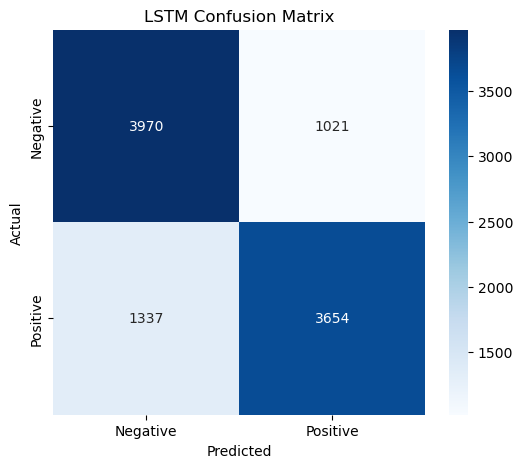

In [ ]:
cm_lstm = confusion_matrix(
    y_test,
    lstm_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
print(
    classification_report(
        y_test,
        lstm_pred,
        target_names=[
            "Negative",
            "Positive"
        ]
    )
)

              precision    recall  f1-score   support

    Negative       0.75      0.80      0.77      4991
    Positive       0.78      0.73      0.76      4991

    accuracy                           0.76      9982
   macro avg       0.76      0.76      0.76      9982
weighted avg       0.76      0.76      0.76      9982



In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "GloVe + LSTM"
    ],

    "Accuracy": [
        lr_accuracy * 100,
        lstm_accuracy * 100
    ],

    "Precision": [
        lr_precision * 100,
        lstm_precision * 100
    ],

    "Recall": [
        lr_recall * 100,
        lstm_recall * 100
    ],

    "F1 Score": [
        lr_f1 * 100,
        lstm_f1 * 100
    ],

    "ROC-AUC": [
        lr_auc,
        lstm_auc
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,TF-IDF + Logistic Regression,77.860148,77.583813,78.361050,77.970494,0.859031
1,GloVe + LSTM,76.377479,78.160428,73.211781,75.605214,0.834851


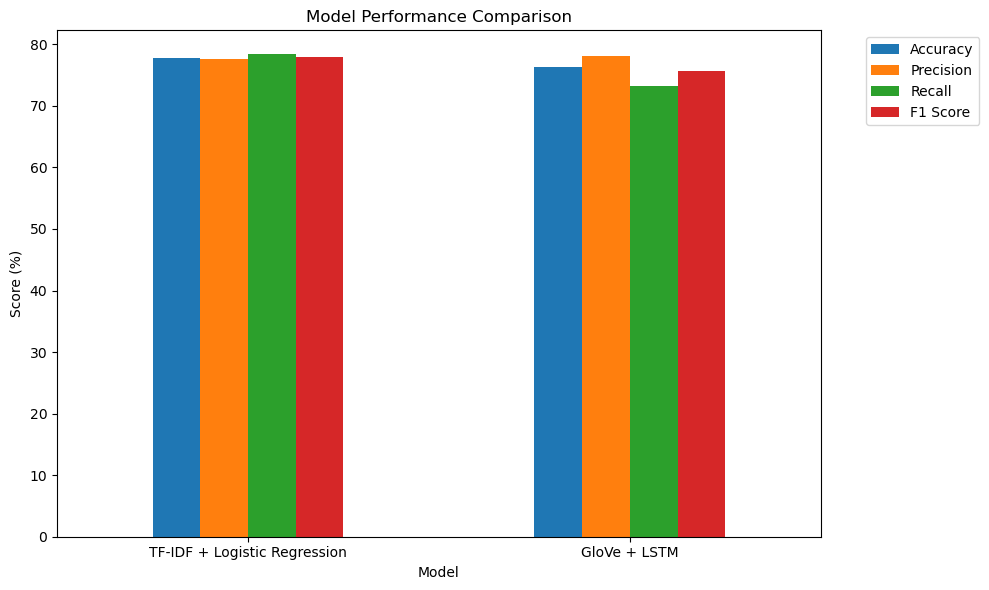

In [ ]:
comparison_plot = comparison.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
]

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.xticks(rotation=0)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

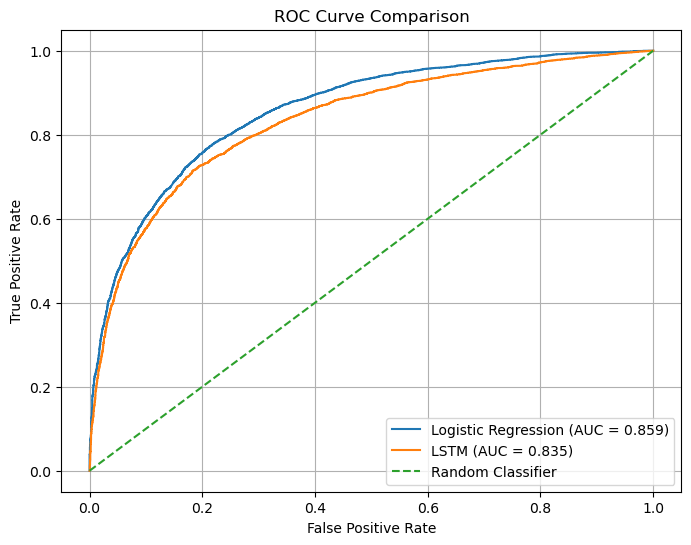

In [ ]:
fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    lr_prob
)

fpr_lstm, tpr_lstm, _ = roc_curve(
    y_test,
    lstm_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {lr_auc:.3f})"
)

plt.plot(
    fpr_lstm,
    tpr_lstm,
    label=f"LSTM (AUC = {lstm_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
results = pd.DataFrame({
    "tweet": X_test.values,
    "actual": y_test.values,
    "probability_positive": lstm_prob,
    "prediction": lstm_pred
})

results["confidence"] = np.where(
    results["prediction"] == 1,
    results["probability_positive"],
    1 - results["probability_positive"]
)

wrong_predictions = results[
    results["actual"] != results["prediction"]
].copy()

confidently_wrong = wrong_predictions.sort_values(
    "confidence",
    ascending=False
).head(10)

print(
    confidently_wrong[
        [
            "tweet",
            "actual",
            "prediction",
            "confidence"
        ]
    ].to_string(index=False)
)

                                                                                                                       tweet  actual  prediction  confidence
                                            follow friday: following more people then followers follow me? woot followfriday       0           1    1.000000
                                                           nursing a toothache hurts like a bitch i need 2 some donut loving       1           0    1.000000
 nice family swim at splash despite general public aka rude inconsiderant adults sod the draft let s forcibly teach courtesy       0           1    1.000000
                                            stockings are bloody itchy listening to miley hopes elyse had a bad day jks hehe       1           0    0.999997
      went to the costume shop over the mountain they have some nice stuff too sexy queen outfits for people with tiny asses       0           1    0.999995
                                                          

In [ ]:
display_wrong = confidently_wrong.copy()

display_wrong["actual"] = display_wrong[
    "actual"
].map({
    0: "Negative",
    1: "Positive"
})

display_wrong["prediction"] = display_wrong[
    "prediction"
].map({
    0: "Negative",
    1: "Positive"
})

display_wrong[
    [
        "tweet",
        "actual",
        "prediction",
        "confidence"
    ]
]

,tweet,actual,prediction,confidence
1859,i hope one day u answer me by twitter my dream...,Positive,Negative,0.500001
5944,wow i m was kinda hppy tooo not have hater but...,Positive,Negative,0.500001
8085,got to go home after 20 mins at work at 6:20 a...,Positive,Negative,0.500001
1710,i will be changing the picture of the flip flo...,Positive,Negative,0.500001
3180,ohh mannn i m a work a holic haha no day off t...,Positive,Negative,0.500001
590,is about to sit back and watch the latest epis...,Positive,Negative,0.500001
1461,today wasn t so bad i started reading just lis...,Positive,Negative,0.500001
7170,kobe you re the best kobe you re the best kobe...,Positive,Negative,0.500000
7183,i ll try it and tell you if it s as bad as it ...,Positive,Negative,0.500000
8252,i love the catcher in the rye and twilight but...,Positive,Negative,0.500000


In [ ]:
trend_data = data.copy()

trend_data["model_probability"] = lstm_model.predict(
    pad_sequences(
        tokenizer.texts_to_sequences(
            trend_data["clean_text"]
        ),
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    ),
    verbose=0
).ravel()

trend_data["date_only"] = trend_data[
    "date"
].dt.date

trend_data = trend_data.dropna(
    subset=["date_only"]
)

print("Trend data prepared.")

Trend data prepared.


In [ ]:
min_date = trend_data["date_only"].min()

max_date = trend_data["date_only"].max()

print("Available date range:")
print(min_date, "to", max_date)
start_date = trend_data["date_only"].min()

end_date = start_date + pd.Timedelta(
    days=29
)

thirty_days = trend_data[
    (
        trend_data["date_only"] >= start_date
    )
    &
    (
        trend_data["date_only"] <= end_date
    )
].copy()

print(
    "Tweets in 30-day period:",
    len(thirty_days)
)

Available date range:
2009-04-06 to 2009-06-25
Tweets in 30-day period: 5779


In [ ]:
daily_sentiment = (
    thirty_days
    .groupby("date_only")[
        "model_probability"
    ]
    .mean()
    .reset_index()
)

daily_sentiment.columns = [
    "date",
    "average_sentiment"
]

daily_sentiment

,date,average_sentiment
0,2009-04-06,0.526628
1,2009-04-07,0.547566
2,2009-04-17,0.514630
3,2009-04-18,0.546981
4,2009-04-19,0.533344
5,2009-04-20,0.543243
6,2009-04-21,0.525232
7,2009-05-01,0.551763
8,2009-05-02,0.538134
9,2009-05-03,0.551723


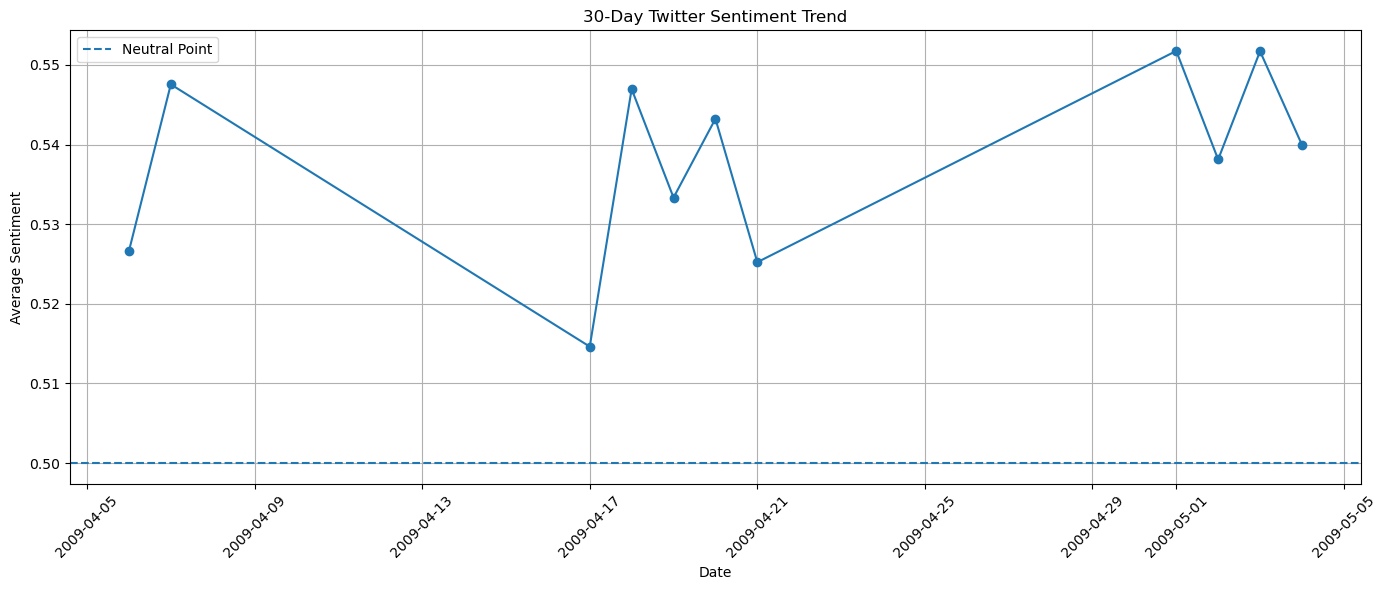

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_sentiment["date"],
    daily_sentiment["average_sentiment"],
    marker="o"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Neutral Point"
)

plt.title(
    "30-Day Twitter Sentiment Trend"
)

plt.xlabel("Date")
plt.ylabel("Average Sentiment")

plt.xticks(rotation=45)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()

In [ ]:
daily_sentiment["change"] = (
    daily_sentiment["average_sentiment"]
    .diff()
    .abs()
)

spikes = daily_sentiment.sort_values(
    "change",
    ascending=False
).head(5)

spikes

,date,average_sentiment,change
2,2009-04-17,0.514630,0.032936
3,2009-04-18,0.546981,0.032351
7,2009-05-01,0.551763,0.026531
1,2009-04-07,0.547566,0.020937
6,2009-04-21,0.525232,0.018011


In [ ]:
for _, spike in spikes.iterrows():

    spike_date = spike["date"]

    tweets_on_date = thirty_days[
        thirty_days["date_only"] == spike_date
    ]

    print("\nDate:", spike_date)
    print(
        "Average sentiment:",
        round(
            spike["average_sentiment"],
            3
        )
    )

    for tweet in tweets_on_date[
        "text"
    ].head(3):

        print(
            "-",
            tweet
        )


Date: 2009-04-17
Average sentiment: 0.515
- Korean foods were delicious, now time for Beer Station and AI, my hands smell like sweet delicious meat 
- @SlantedSmiley fine its OURS 
- going to bed, so tired! wishing it was tuesday night so i could watch idol.  anyway, night. xox

Date: 2009-04-18
Average sentiment: 0.547
- @busybeeblogger I remember u saying when u like a guy u r giggly 
- says BINWEI IS RETARDED!  http://plurk.com/p/ox5l6
- @majeakann I'm sure it is! to you too!  g'night!

Date: 2009-05-01
Average sentiment: 0.552
- Good morning twitter 
- @samchez haha  I know right! I &lt;3 frankston.
- Hungry and tired  I need a massage, maybe i'll pay my sis to give me one....lol

Date: 2009-04-07
Average sentiment: 0.548
- welp, bedtime for me guys. night 
- http://www.myspace.com/loser_kids_girl21 Woot changed Myspace profile.... Check it out!! 
- @ILikeBubbles Hi hi bubbly one 

Date: 2009-04-21
Average sentiment: 0.525
- Working, listening to The Edge radio station, awesome st

In [ ]:
# ============================================================
# USER TWEET SENTIMENT PREDICTION
# ============================================================

def predict_sentiment(tweet):

    # Clean tweet
    cleaned = clean_tweet(tweet)

    # Convert to sequence
    sequence = tokenizer.texts_to_sequences(
        [cleaned]
    )

    # Pad
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    # Convert to NumPy
    padded = np.asarray(
        padded,
        dtype=np.int32
    )

    # Predict
    probability = lstm_model.predict(
        padded,
        verbose=0
    )[0][0]

    # Sentiment
    if probability >= 0.5:
        sentiment = "Positive"
        confidence = probability
    else:
        sentiment = "Negative"
        confidence = 1 - probability

    return sentiment, confidence

In [ ]:
user_tweet = input(
    "Enter a tweet: "
)

sentiment, confidence = predict_sentiment(
    user_tweet
)

print("\nPrediction Result")
print("-" * 30)

print("Tweet:", user_tweet)

print("Sentiment:", sentiment)

print(
    f"Confidence: {confidence * 100:.2f}%"
)

Enter a tweet:  This is the worst experience I have ever had. I am extremely disappointed.



Prediction Result
------------------------------
Tweet: This is the worst experience I have ever had. I am extremely disappointed.
Sentiment: Negative
Confidence: 100.00%
